In [23]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

import sys

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

In [24]:
# Directorul principal al proiectului
BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Calea catre datasetul curatat
DATA_FILE = BASE_DIR / "data" / "apartments_clean.csv"

# Incarcam datasetul
df = pd.read_csv(DATA_FILE)

print("Dataset incarcat cu succes!")
print("Dimensiune:", df.shape)

display(df.head())

Dataset incarcat cu succes!
Dimensiune: (3354, 7)


,Nr Camere,Suprafata,Etaj,Total Etaje,Sector,Scor,Pret
0,4,108.00,2,3,4,5,83000
1,1,41.00,1,8,1,1,39900
2,3,63.52,1,3,2,3,84900
3,1,33.00,3,10,5,1,45500
4,2,62.00,5,9,5,5,54900


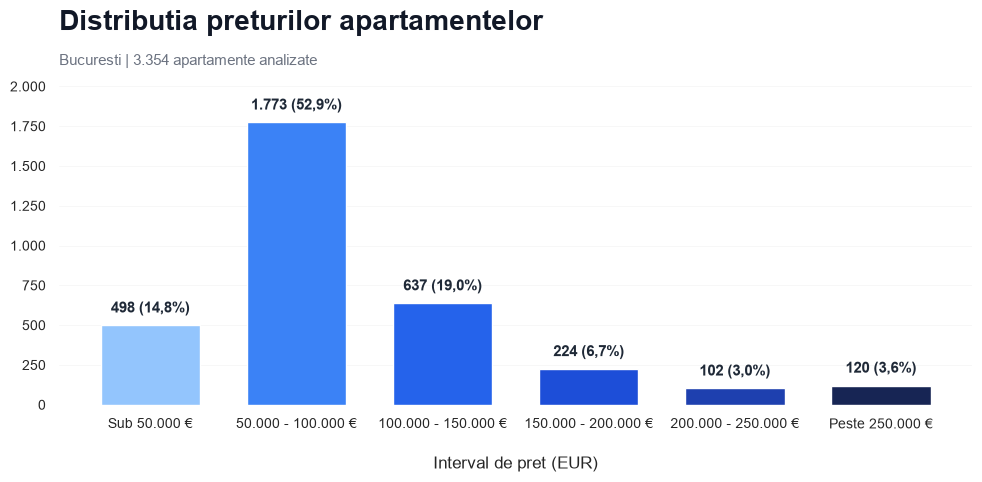

Preț minim: 19.500 €   |   Preț maxim: 495.000 €


In [25]:
# Distributia preturilor pe apartamente 
# Configuram aspectul graficului
sns.set_theme(style="white", font_scale=1.05)

# Definim intervalele de pret
limite = [0, 50000, 100000, 150000, 200000, 250000, np.inf]
etichete = [
    "Sub 50.000 €",
    "50.000 - 100.000 €",
    "100.000 - 150.000 €",
    "150.000 - 200.000 €",
    "200.000 - 250.000 €",
    "Peste 250.000 €"
]

# Grupam apartamentele pe intervale
intervale = pd.cut(
    df["Pret"],
    bins=limite,
    labels=etichete,
    include_lowest=True
)
distributie = intervale.value_counts().sort_index()
total_apartamente = distributie.sum()

# Cream figura
fig, ax = plt.subplots(figsize=(10, 5))
culori = [
    "#93c5fd",
    "#3b82f6",
    "#2563eb",
    "#1d4ed8",
    "#1e40af",
    "#172554"
]
bare = ax.bar(
    distributie.index.astype(str),
    distributie.values,
    color=culori,
    width=0.68
)

# Afisam numarul si procentul de apartamente
for bara in bare:
    valoare = int(bara.get_height())
    procent = valoare / total_apartamente * 100
    text_eticheta = (
        f"{valoare:,}".replace(",", ".")
        + f" ({procent:.1f}%)".replace(".", ",", 1)
    )
    ax.annotate(
        text_eticheta,
        (bara.get_x() + bara.get_width() / 2, valoare),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#1f2937",
        xytext=(0, 7),
        textcoords="offset points"
    )

# Titlu si subtitlu
ax.set_title(
    "Distributia preturilor apartamentelor",
    fontsize=20,
    fontweight="bold",
    loc="left",
    pad=30,
    color="#111827"
)
ax.text(
    0, 1.02,
    f"Bucuresti | {total_apartamente:,} apartamente analizate".replace(",", "."),
    transform=ax.transAxes,
    fontsize=11,
    color="#6b7280"
)

# Configuram axele
ax.set_xlabel(
    "Interval de pret (EUR)",
    fontsize=12,
    labelpad=18
)
ax.set_ylabel("")
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x:,.0f}".replace(",", ".")
    )
)

# Stilizam graficul
ax.grid(
    axis="y",
    linestyle="-",
    linewidth=0.7,
    alpha=0.15
)

ax.set_axisbelow(True)
ax.set_ylim(0, distributie.max() * 1.18)

sns.despine(left=True, bottom=True)

plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

# Statistici esentiale 
pret_min = f"{df['Pret'].min():,.0f}".replace(",", ".")
pret_max = f"{df['Pret'].max():,.0f}".replace(",", ".")

print(f"Preț minim: {pret_min} €   |   Preț maxim: {pret_max} €")



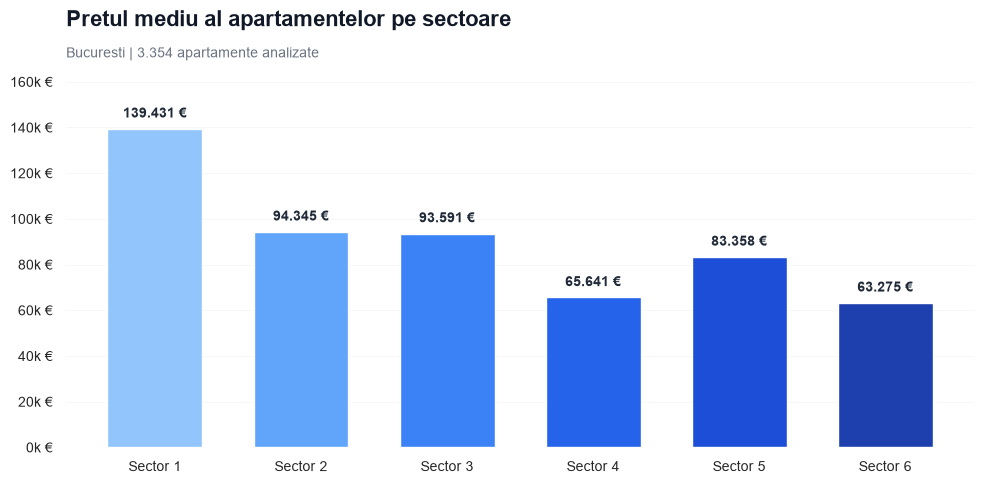

Cel mai scump: Sector 1 (139.431 €)   |   Cel mai ieftin: Sector 6 (63.275 €)


In [26]:
# Pretul mediu al apartamentelor pe sectoare
# Calculam pretul mediu pentru fiecare sector
preturi_sectoare = (
    df.groupby("Sector")["Pret"]
    .mean()
    .sort_index()
)

# Configuram aspectul graficului
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(10, 5))
culori = [
    "#93c5fd",
    "#60a5fa",
    "#3b82f6",
    "#2563eb",
    "#1d4ed8",
    "#1e40af"
]

# Cream graficul
bare = ax.bar(
    [f"Sector {sector}" for sector in preturi_sectoare.index],
    preturi_sectoare.values,
    color=culori,
    width=0.65
)

# Afisam preturile deasupra barelor
for bara in bare:
    valoare = bara.get_height()
    ax.annotate(
        f"{valoare:,.0f}".replace(",", ".") + " €",
        (bara.get_x() + bara.get_width() / 2, valoare),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#1f2937",
        xytext=(0, 6),
        textcoords="offset points"
    )

# Titlu si subtitlu
ax.set_title(
    "Pretul mediu al apartamentelor pe sectoare",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=28,
    color="#111827"
)
ax.text(
    0, 1.02,
    f"Bucuresti | {len(df):,} apartamente analizate".replace(",", "."),
    transform=ax.transAxes,
    fontsize=10,
    color="#6b7280"
)

# Configuram axele
ax.set_xlabel("")
ax.set_ylabel("")
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x / 1000:,.0f}k €"
    )
)

# Stilizam graficul
ax.grid(
    axis="y",
    linestyle="-",
    linewidth=0.7,
    alpha=0.15
)
ax.set_axisbelow(True)
ax.set_ylim(0, preturi_sectoare.max() * 1.20)
sns.despine(left=True, bottom=True)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

# Statistici esentiale pe o singura linie
sector_scump = preturi_sectoare.idxmax()
sector_ieftin = preturi_sectoare.idxmin()
pret_max = f"{preturi_sectoare.max():,.0f}".replace(",", ".")
pret_min = f"{preturi_sectoare.min():,.0f}".replace(",", ".")

print(
    f"Cel mai scump: Sector {sector_scump} ({pret_max} €)"
    f"   |   Cel mai ieftin: Sector {sector_ieftin} ({pret_min} €)"
)


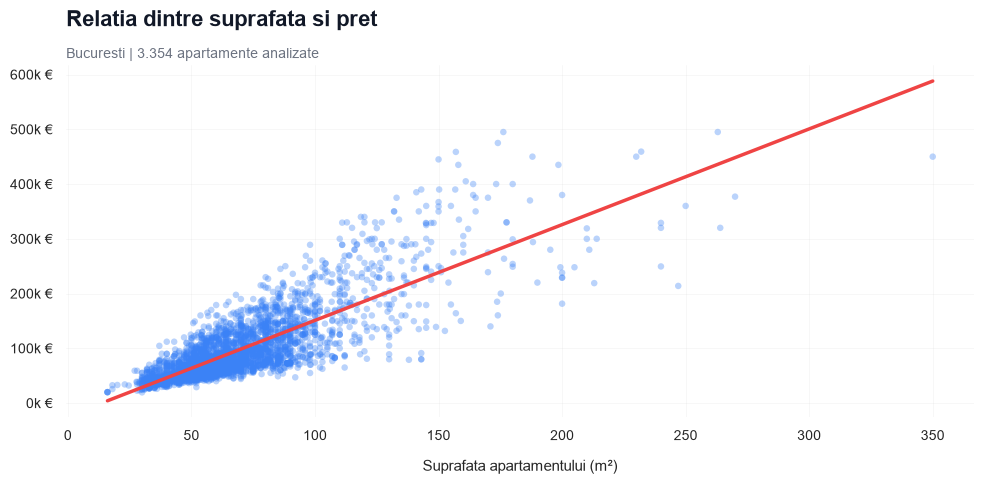

Suprafata: 16 - 350 m²   |   Corelatie suprafata-pret: 0.81


In [27]:
# Relatia dintre suprafata si pret
# Configuram aspectul graficului
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(10, 5))

# Cream graficul cu linie de regresie
sns.regplot(
    data=df,
    x="Suprafata",
    y="Pret",
    ax=ax,
    scatter_kws={
        "color": "#3b82f6",
        "alpha": 0.35,
        "s": 22,
        "edgecolor": "none"
    },
    line_kws={
        "color": "#ef4444",
        "linewidth": 2.5
    },
    ci=None
)

# Titlu si subtitlu
ax.set_title(
    "Relatia dintre suprafata si pret",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=28,
    color="#111827"
)
ax.text(
    0, 1.02,
    f"Bucuresti | {len(df):,} apartamente analizate".replace(",", "."),
    transform=ax.transAxes,
    fontsize=10,
    color="#6b7280"
)

# Configuram axele
ax.set_xlabel(
    "Suprafata apartamentului (m²)",
    fontsize=11,
    labelpad=12
)
ax.set_ylabel("")

# Afisam preturile in mii de euro
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1000:.0f}k €")
)

# Stilizam graficul
ax.grid(
    linestyle="-",
    linewidth=0.7,
    alpha=0.15
)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

# Statistici esentiale
corelatie = df["Suprafata"].corr(df["Pret"])

suprafata_min = f"{df['Suprafata'].min():g}"
suprafata_max = f"{df['Suprafata'].max():g}"

print(
    f"Suprafata: {suprafata_min} - {suprafata_max} m²"
    f"   |   Corelatie suprafata-pret: {corelatie:.2f}"
)


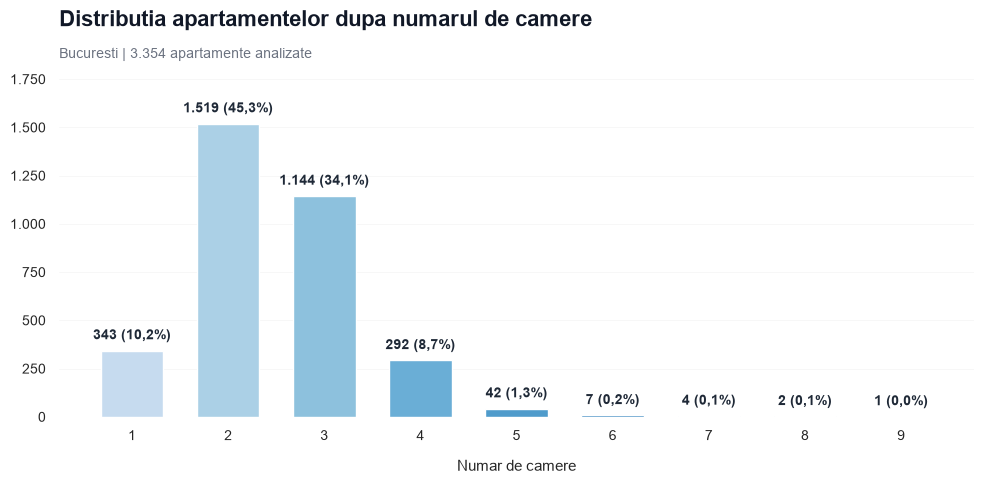

Cele mai frecvente: 2 camere   |   Numar apartamente: 1.519


In [28]:
# Distributia apartamentelor dupa numarul de camere
# Calculam numarul de apartamente pentru fiecare categorie
distributie_camere = (
    df["Nr Camere"]
    .value_counts()
    .sort_index()
)
total_apartamente = distributie_camere.sum()

# Configuram aspectul graficului
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(10, 5))

# Cream graficul
culori = sns.color_palette(
    "Blues",
    n_colors=len(distributie_camere) + 2
)[2:]
bare = ax.bar(
    distributie_camere.index.astype(str),
    distributie_camere.values,
    color=culori,
    width=0.65
)

# Afisam numarul si procentul de apartamente
for bara in bare:
    valoare = int(bara.get_height())
    procent = valoare / total_apartamente * 100

    eticheta = (
        f"{valoare:,}".replace(",", ".")
        + f" ({procent:.1f}%)".replace(".", ",")
    )

    ax.annotate(
        eticheta,
        (bara.get_x() + bara.get_width() / 2, valoare),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#1f2937",
        xytext=(0, 6),
        textcoords="offset points"
    )

# Titlu si subtitlu
ax.set_title(
    "Distributia apartamentelor dupa numarul de camere",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=28,
    color="#111827"
)
ax.text(
    0, 1.02,
    f"Bucuresti | {total_apartamente:,} apartamente analizate".replace(",", "."),
    transform=ax.transAxes,
    fontsize=10,
    color="#6b7280"
)

# Configuram axele
ax.set_xlabel(
    "Numar de camere",
    fontsize=11,
    labelpad=12
)
ax.set_ylabel("")
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x:,.0f}".replace(",", ".")
    )
)

# Stilizam graficul
ax.grid(
    axis="y",
    linestyle="-",
    linewidth=0.7,
    alpha=0.15
)
ax.set_axisbelow(True)
ax.set_ylim(0, distributie_camere.max() * 1.20)
sns.despine(left=True, bottom=True)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

# Statistici esentiale
camere_frecvente = distributie_camere.idxmax()
numar_frecvente = distributie_camere.max()

print(
    f"Cele mai frecvente: {camere_frecvente} camere"
    f"   |   Numar apartamente: {numar_frecvente:,}".replace(",", ".")
)


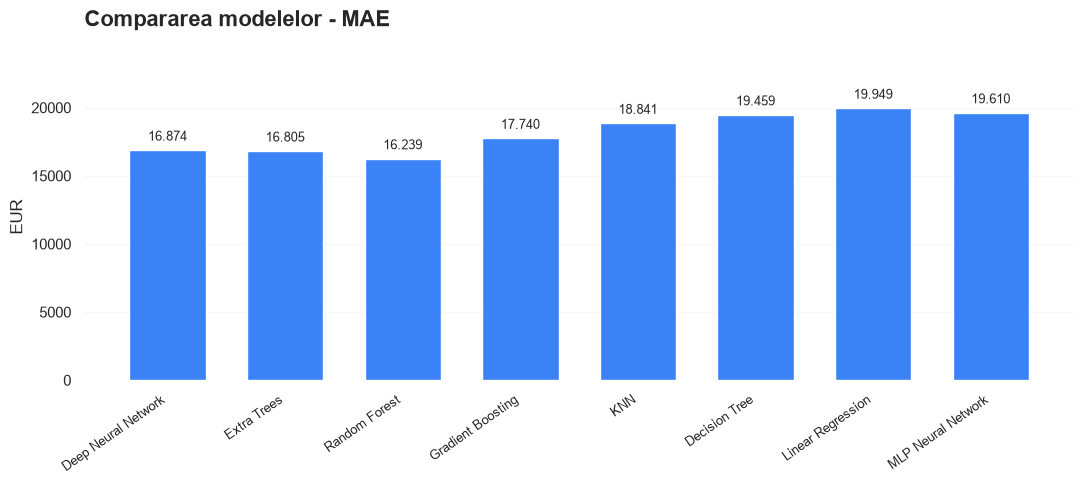

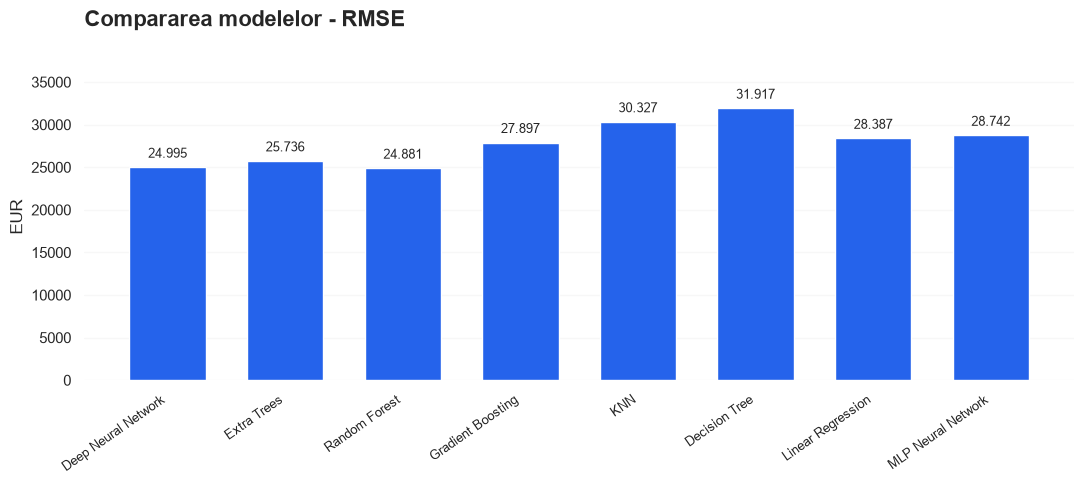

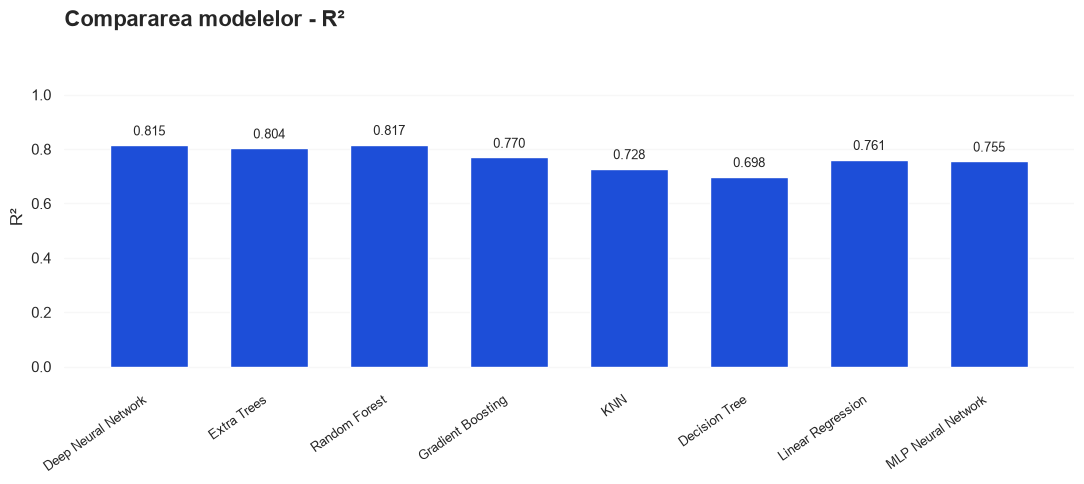

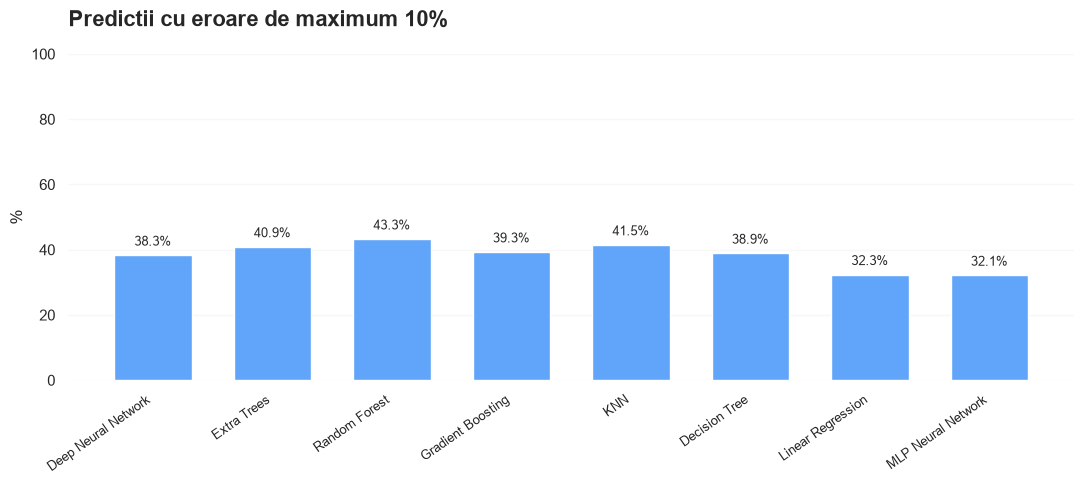

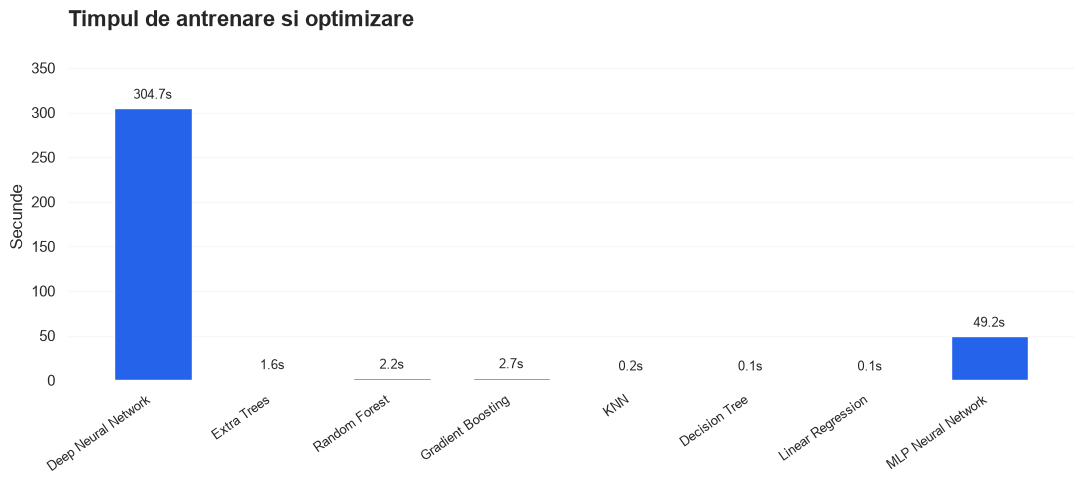

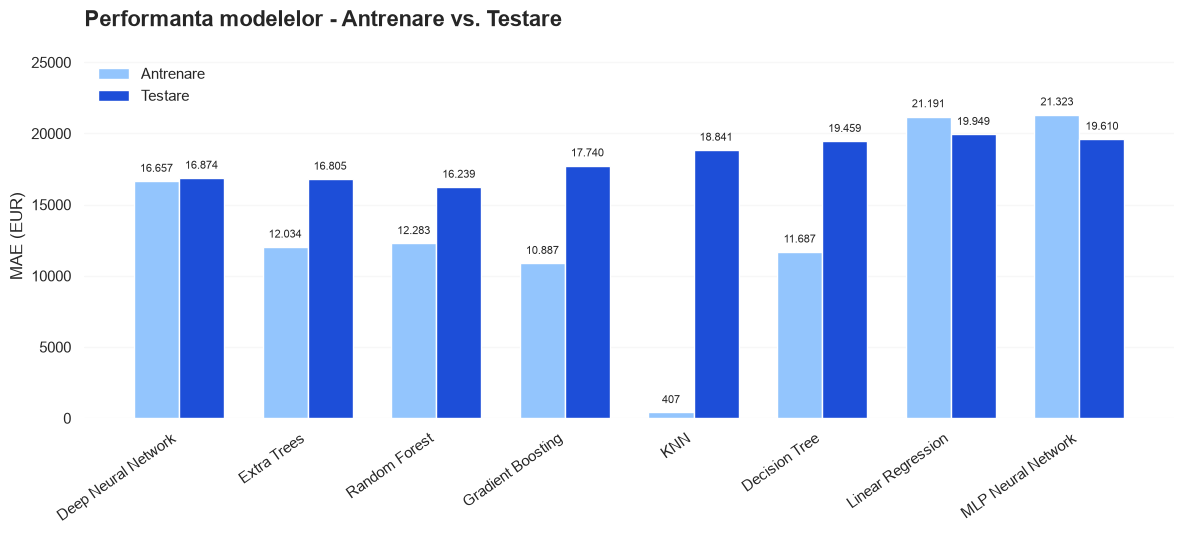


CEL MAI BUN MODEL: Deep Neural Network
MAE pe validare: 17,202.25 EUR


In [29]:
# EVALUAREA CELOR 8 MODELE 
# Incarcam rezultatele
BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

RESULTS_DIR = BASE_DIR / "models" / "results"

train_df = pd.read_csv(RESULTS_DIR / "training_metrics.csv")
val_df = pd.read_csv(RESULTS_DIR / "validation_metrics.csv")
test_df = pd.read_csv(RESULTS_DIR / "test_metrics.csv")

# Pastram ordinea dupa performanta pe validare
ordine = val_df.sort_values("MAE")["Model"].tolist()

train_df = train_df.set_index("Model").loc[ordine]
val_df = val_df.set_index("Model").loc[ordine]
test_df = test_df.set_index("Model").loc[ordine]

sns.set_theme(style="white")

# Functie pentru graficele cu o singura metrica
def grafic_metrica(coloana, titlu, unitate, culoare):

    valori = test_df[coloana]

    fig, ax = plt.subplots(figsize=(11, 5))

    bare = ax.bar(
        valori.index,
        valori.values,
        color=culoare,
        width=0.65
    )

    for bara, valoare in zip(bare, valori):

        if coloana == "R2":
            eticheta = f"{valoare:.3f}"
        elif unitate == "%":
            eticheta = f"{valoare:.1f}%"
        else:
            eticheta = f"{valoare:,.0f}".replace(",", ".")

        ax.annotate(
            eticheta,
            (bara.get_x() + bara.get_width() / 2, valoare),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 5),
            textcoords="offset points"
        )

    ax.set_title(
        titlu,
        fontsize=16,
        fontweight="bold",
        loc="left",
        pad=20
    )

    ax.set_ylabel(unitate)
    ax.set_xlabel("")

    plt.xticks(rotation=35, ha="right", fontsize=9)

    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    minim = min(0, valori.min())
    maxim = valori.max()

    if coloana == "R2":
        ax.set_ylim(minim - 0.05, max(1, maxim) + 0.15)
    elif unitate == "%":
        ax.set_ylim(0, max(100, maxim * 1.15))
    else:
        ax.set_ylim(0, maxim * 1.20)

    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()


# GRAFICUL 1 - MAE
grafic_metrica(
    "MAE",
    "Compararea modelelor - MAE",
    "EUR",
    "#3b82f6"
)

# GRAFICUL 2 - RMSE
grafic_metrica(
    "RMSE",
    "Compararea modelelor - RMSE",
    "EUR",
    "#2563eb"
)

# GRAFICUL 3 - R2
grafic_metrica(
    "R2",
    "Compararea modelelor - R²",
    "R²",
    "#1d4ed8"
)

# GRAFICUL 4 - Predictii in +/- 10%
grafic_metrica(
    "Within_10pct",
    "Predictii cu eroare de maximum 10%",
    "%",
    "#60a5fa"
)

# GRAFICUL 5 - TIMPUL DE ANTRENARE SI OPTIMIZARE
fig, ax = plt.subplots(figsize=(11, 5))
timpi = val_df["Training_time_sec"]
bare = ax.bar(
    timpi.index,
    timpi.values,
    color="#2563eb",
    width=0.65
)
for bara in bare:
    valoare = bara.get_height()
    ax.annotate(
        f"{valoare:.1f}s",
        (bara.get_x() + bara.get_width() / 2, valoare),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 5),
        textcoords="offset points"
    )
ax.set_title(
    "Timpul de antrenare si optimizare",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=20
)
ax.set_ylabel("Secunde")
ax.set_xlabel("")
plt.xticks(rotation=35, ha="right", fontsize=9)
ax.set_ylim(0, max(timpi.max() * 1.20, 1))
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

# GRAFICUL 6 - ANTRENARE VS TESTARE (MAE)
fig, ax = plt.subplots(figsize=(12, 5.5))

x = np.arange(len(ordine))
latime = 0.35

bare_train = ax.bar(
    x - latime / 2,
    train_df["MAE"],
    latime,
    label="Antrenare",
    color="#93c5fd"
)

bare_test = ax.bar(
    x + latime / 2,
    test_df["MAE"],
    latime,
    label="Testare",
    color="#1d4ed8"
)

for bare in [bare_train, bare_test]:
    for bara in bare:
        valoare = bara.get_height()

        ax.annotate(
            f"{valoare:,.0f}".replace(",", "."),
            (bara.get_x() + bara.get_width() / 2, valoare),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 5),
            textcoords="offset points"
        )

ax.set_title(
    "Performanta modelelor - Antrenare vs. Testare",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xticks(x)
ax.set_xticklabels(ordine, rotation=35, ha="right")

ax.set_ylabel("MAE (EUR)")
ax.set_xlabel("")
ax.legend(frameon=False)

ax.set_ylim(
    0,
    max(train_df["MAE"].max(), test_df["MAE"].max()) * 1.20
)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

# MODELUL CASTIGATOR
best_model = val_df["MAE"].idxmin()
best_mae = val_df.loc[best_model, "MAE"]

print("\n" + "=" * 60)
print(f"CEL MAI BUN MODEL: {best_model}")
print(f"MAE pe validare: {best_mae:,.2f} EUR")
print("=" * 60)


In [ ]:
# FORMULAR INTERACTIV - PREDICTIA PRETULUI

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

if str(BASE_DIR / "src") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "src"))

from predict import ApartmentPredictor

# Incarcam modelul o singura data
predictor = ApartmentPredictor()

# Campurile formularului
suprafata = widgets.FloatText(
    value=75,
    description="Suprafata:",
    style={"description_width": "120px"}
)

camere = widgets.Dropdown(
    options=list(range(1, 10)),
    value=3,
    description="Camere:",
    style={"description_width": "120px"}
)

etaj = widgets.IntText(
    value=4,
    description="Etaj:",
    style={"description_width": "120px"}
)

total_etaje = widgets.IntText(
    value=10,
    description="Total etaje:",
    style={"description_width": "120px"}
)

sector = widgets.Dropdown(
    options=[1, 2, 3, 4, 5, 6],
    value=3,
    description="Sector:",
    style={"description_width": "120px"}
)

scor = widgets.FloatText(
    value=5,
    description="Scor:",
    style={"description_width": "120px"}
)

# Butonul de predictie
buton = widgets.Button(
    description="Estimeaza pretul",
    button_style="primary",
    icon="calculator",
    layout=widgets.Layout(width="220px", height="42px")
)

rezultat = widgets.Output()


def estimeaza_pret(b):

    with rezultat:
        clear_output(wait=True)

        if suprafata.value <= 0:
            print("Suprafata trebuie sa fie pozitiva.")
            return

        if total_etaje.value < 1:
            print("Numarul total de etaje trebuie sa fie pozitiv.")
            return

        if etaj.value > total_etaje.value:
            print("Etajul nu poate depasi numarul total de etaje.")
            return

        pret = predictor.predict(
            suprafata=suprafata.value,
            camere=camere.value,
            etaj=etaj.value,
            total_etaje=total_etaje.value,
            sector=sector.value,
            scor=scor.value
        )

        pret_formatat = f"{pret:,.0f}".replace(",", ".")

        display(HTML(f"""
        <div style="
            background:#eff6ff;
            border:1px solid #bfdbfe;
            border-radius:12px;
            padding:22px;
            margin-top:15px;
            font-family:Arial;
        ">
            <div style="color:#475569;font-size:14px;">
                Pret estimat pentru apartament
            </div>

            <div style="
                color:#1d4ed8;
                font-size:32px;
                font-weight:bold;
                margin-top:8px;
            ">
                {pret_formatat} €
            </div>

            <div style="
                color:#64748b;
                font-size:12px;
                margin-top:12px;
            ">
                Model utilizat: {predictor.model_name}
            </div>
        </div>
        """))


buton.on_click(estimeaza_pret)

# Afisam formularul
display(HTML("""
<h2 style="margin-bottom:6px;">
    Predictia pretului unui apartament
</h2>
<p style="color:#64748b;">
    Introdu caracteristicile apartamentului din Bucuresti.
</p>
"""))

formular = widgets.VBox([
    widgets.HBox([suprafata, camere]),
    widgets.HBox([etaj, total_etaje]),
    widgets.HBox([sector, scor]),
    buton,
    rezultat
], layout=widgets.Layout(gap="12px"))

display(formular)